# Урок 15. Цвет с разных сторон

[План курса](../../README_ru.md)

Серый шар остаётся серым при обходе вокруг него. А вот маленькое пятно на лакированной чашке на одном снимке краснее, чем на соседнем. У неподвижной точки сцены могут оказаться разные наблюдаемые цвета. Начнём с пятна, у которого меняется только красный канал.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo

## Кадр, в котором двигается только цвет

Камера всё время смотрит на центр одного круглого пятна с одинаковым масштабом по трём осям. Расстояние до него тоже постоянно. Слева у пятна фиксированный RGB. Справа в тот же RGB добавляется число, зависящее от направления. У центра непрозрачность равна единице, так что там виден цвет самого пятна. По краям в него подмешивается белый фон.

Если обнулить три направленных коэффициента, правый кадр повторит левый при любом азимуте. По одному ненулевому коэффициенту легко увидеть, какая сторона сферы станет краснее. Наклон камеры открывает направление по вертикали.

In [2]:
display(demo.experiment(15, "ru"))

## Направление длины один

Пусть центр камеры $K=(-3,0,0)$, центр пятна $P=(0,0,4)$. Стрелка **от камеры к пятну** равна $P-K=(3,0,4)$. По теореме Пифагора длина $r=\sqrt{3^2+0^2+4^2}=\sqrt{25}=5$. Деление каждой компоненты на пять даёт $d=(0.6,0,0.8)$. Длина теперь единица, ведь $0.6^2+0.8^2=1$. Направление безразмерно, а расстояние больше не меняет цвет. Камера ещё в пяти единицах на той же линии даст ту же стрелку после нормировки.

Все возможные концы таких единичных стрелок лежат на поверхности сферы. Если камера окажется ровно в центре пятна, стрелка будет нулевой и направления не получится. Рендерер пропускает такую точку ещё на проверке глубины. Положительное $y$ здесь направлено вниз в мире исходной камеры. Коэффициенты цвета относятся к мировым осям, поэтому поворот корпуса камеры на месте сам по себе не меняет цвет точки.

In [3]:
direction = np.array([3., 0., 4.])
print(direction / np.linalg.norm(direction))
print(np.round(sr.sh_basis(direction), 6))
np.testing.assert_allclose(sr.sh_basis(direction), sr.sh_basis(2*direction))

[0.6 0.  0.8]
[ 0.282095 -0.        0.390882 -0.293162]


## Четыре карты одной сферы

**Сферическая гармоника** здесь — заранее известное правило, которое по направлению выдаёт число. Весь набор таких правил служит базисом. Для нашей первой карты число одинаково по всей сфере. Ещё три карты плавно меняют знак между противоположными сторонами. Рисунок одной карты задаёт **функция**, а сколько этого рисунка пойдёт в цвет конкретного пятна — **коэффициент**.

В соглашении рендерера Kerbl et al. первые четыре действительные функции идут в порядке:

$$
(Y_0,Y_y,Y_z,Y_x)=(C_0,-C_1d_y,+C_1d_z,-C_1d_x).
$$

Здесь $C_0=1/\sqrt{4\pi}\approx0.282095$ и $C_1=\sqrt{3/(4\pi)}\approx0.488603$. Число $\pi\approx3.14159$ связывает радиус и длину окружности. Выбор этих постоянных уравнивает суммарный квадрат каждой функции по сфере. Например, площадь сферы радиуса один равна $4\pi$. Для постоянной карты $4\pi C_0^2=1$. Для карты $x$ среднее значение $x^2$ по сфере равно $1/3$: оси равноправны, а $x^2+y^2+z^2=1$. Тогда $4\pi C_1^2/3=1$. В самой картинке константа и сила коэффициента всегда работают вместе.

В направлении $(0.6,0,0.8)$ карты дают $(0.282095,0,0.390882,-0.293162)$. Отрицательное значение карты допустимо. Оно означает вычитание соответствующего вклада, а не отрицательную яркость экрана.

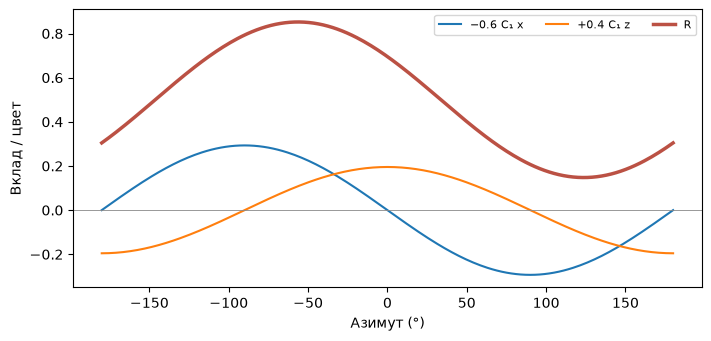

In [4]:
fig = demo.harmonic_curve("ru")
display(fig)
plt.close(fig)

## Из карт — в красный канал

Пусть для красного заданы четыре коэффициента $a=(0,0,0.4,0.6)$. Постоянный сдвиг $0.5$ в кодировке оригинального GS соответствует серому при всех нулевых коэффициентах. Сначала умножаем попарно карту и коэффициент, затем складываем:

$$
\begin{aligned}
R &= 0.5+a_0Y_0+a_yY_y+a_zY_z+a_xY_x \\
  &= 0.5+0+0+0.4\cdot0.390882+0.6\cdot(-0.293162)\\
  &\approx 0.5+0.156353-0.175897=0.480456.
\end{aligned}
$$

У зелёного и синего коэффициенты нулевые, итоговая тройка $(0.480456,0.5,0.5)$. Если требуется постоянный красный $0.8$, достаточно решить $0.8=0.5+a_0 C_0$: вычитаем $0.5$, делим $0.3$ на $0.282095$, получаем $a_0\approx1.0635$. Коэффициент может быть больше единицы. Для показа мы ограничиваем конечный канал промежутком $[0,1]$. В исходном CUDA-вычислении SH на этой стадии отсекаются только отрицательные значения. Выбор места ограничения важен при обучении на очень ярких цветах.

In [5]:
coeff = np.array([[0,0,0], [0,0,0], [.4,0,0], [.6,0,0]])
for d in ([.6,0,.8], [-.6,0,-.8]):
    print(d, np.round(sr.sh_color(d, coeff), 6))
constant = [[(.8-.5)/sr.C0, 0, 0]]
np.testing.assert_allclose(sr.sh_color([0,0,1], constant), [.8,.5,.5])

[0.6, 0, 0.8] [0.480456 0.5      0.5     ]
[-0.6, 0, -0.8] [0.519544 0.5      0.5     ]


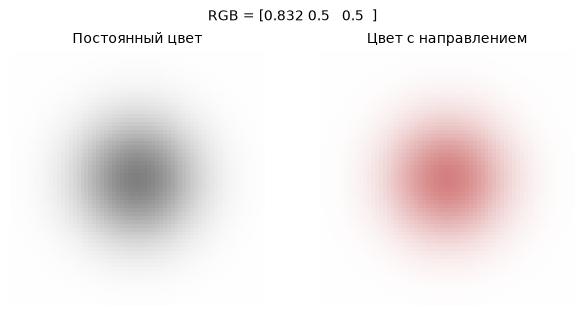

In [6]:
fig = demo.harmonic_figure("ru")
display(fig)
plt.close(fig)

## Сколько значений хранит пятно

Постоянная карта имеет степень 0. Степень 1 добавляет три карты. Суммарно до степени $l$ включительно их $(l+1)^2$. Для $l=1$ получаем $(1+1)^2=4$ коэффициента на канал, всего $4\cdot3=12$ чисел на RGB. При $l=3$ их $16\cdot3=48$. Старшие степени позволяют быстрее менять цвет с направлением. Очень узкий блик по-прежнему трудно уложить в несколько плавных карт. Коэффициенты обучаются по фотографиям; они описывают наблюдаемую зависимость и сами по себе не задают положение лампы. [Определение направления и знаков в исходном рендерере](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/forward.cu).

## Опыты и разбор

Что получится с противоположной стороны сферы? А если поменять принятую стрелку на «от пятна к камере», сохранив тот же внешний вид?

<details><summary>Разбор</summary>

У противоположного направления три линейные карты меняют знак. Наш красный равен $0.5-0.156353+0.175897=0.519544$. Нулевая степень одинакова с обеих сторон. Чтобы перенести модель между двумя противоположными соглашениями, одновременно меняются знаки трёх коэффициентов степени 1; два минуса в каждом произведении сокращаются.

</details>